# Demand Forecasting: Prediction Visualizer & Executive Dashboard

This notebook provides interactive visualisations of model predictions against historical actuals.
It is structured for presenting results to technical and commercial stakeholders.

### Key Highlights:
1. **Product Time Series:** Daily unit sales vs. predicted demand with promotional highlights.
2. **Multi-Family Comparison:** Cross-category demand trajectories within a store.
3. **Cumulative Volume Calibration:** Tracking bias and total demand over the forecast horizon.
4. **Promotional Lift Dynamics:** Quantifying model sensitivity to marketing promotions.
5. **Error Breakdown Matrix:** Store-by-family NWRMSLE performance across perishable ($w=1.25$) and non-perishable ($w=1.00$) categories.

In [1]:
import plotly.io as pio
pio.renderers.default = 'png'
from __future__ import annotations

import json
import sys
from pathlib import Path

import lightgbm as lgb
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import polars as pl

# Ensure project root is accessible
REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.features.aggregations import build_lag_features
from src.features.temporal import build_temporal_features
from src.models.metrics import nwrmsle_numpy

DATA_DIR = REPO_ROOT / "data" / "sample"
MODELS_DIR = REPO_ROOT / "models"

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1. Load Data & Generate Model Predictions

We ingest the benchmark time series, apply the production temporal and lag feature engineering pipeline, and score the dataset with the trained LightGBM booster.

In [2]:
sample_path = DATA_DIR / "train_sample.parquet"
feat_cols_path = MODELS_DIR / "feature_cols.json"
model_path = MODELS_DIR / "lgbm_forecaster.txt"

df_raw = pl.read_parquet(sample_path)
with open(feat_cols_path, encoding="utf-8") as f:
    feature_cols: list[str] = json.load(f)

# Execute feature pipeline
df_feat = build_temporal_features(df_raw.lazy()).collect()
df_feat = build_lag_features(df_feat.lazy(), target_col="unit_sales").collect()
df_clean = df_feat.drop_nulls(subset=feature_cols)

# Predict using booster
booster = lgb.Booster(model_file=str(model_path))
X = df_clean.select(feature_cols).to_numpy()
preds_natural = np.expm1(booster.predict(X)).clip(min=0.0)

df_eval = df_clean.with_columns(pl.Series(name="prediction", values=preds_natural))

print(f"Evaluated rows: {len(df_eval):,}")
print(f"Date window: {df_eval['date'].min()} to {df_eval['date'].max()}")
print(f"Stores: {df_eval['store_nbr'].unique().to_list()}")
print(f"Families: {df_eval['family'].unique().to_list()}")

Evaluated rows: 1,968
Date window: 2017-02-26 to 2017-08-08
Stores: [1, 2, 3]
Families: ['MEATS', 'GROCERY I', 'BEVERAGES', 'PRODUCE']


## 2. Product Time Series: Actual vs. Forecast with Promotions

Below we plot daily unit sales against predictions for a specific store and product family. Promotional days are marked with gold stars to illustrate promotional response.

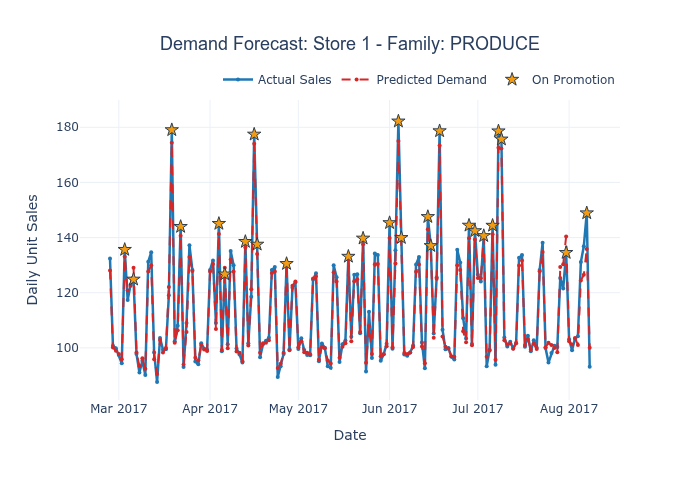

In [3]:
SELECTED_STORE = 1
SELECTED_FAMILY = "PRODUCE"  # Perishable, weight = 1.25

ts_df = (
    df_eval
    .filter((pl.col("store_nbr") == SELECTED_STORE) & (pl.col("family") == SELECTED_FAMILY))
    .sort("date")
    .to_pandas()
)

fig_single = go.Figure()

# Actual sales
fig_single.add_trace(
    go.Scatter(
        x=ts_df["date"],
        y=ts_df["unit_sales"],
        mode="lines+markers",
        name="Actual Sales",
        line=dict(color="#1f77b4", width=2.5),
        marker=dict(size=4),
    )
)

# Predicted sales
fig_single.add_trace(
    go.Scatter(
        x=ts_df["date"],
        y=ts_df["prediction"],
        mode="lines+markers",
        name="Predicted Demand",
        line=dict(color="#d62728", width=2, dash="dash"),
        marker=dict(size=4),
    )
)

# Highlight on-promotion days
promo_days = ts_df[ts_df["onpromotion"] == 1]
if not promo_days.empty:
    fig_single.add_trace(
        go.Scatter(
            x=promo_days["date"],
            y=promo_days["unit_sales"],
            mode="markers",
            name="On Promotion",
            marker=dict(symbol="star", size=10, color="#f39c12", line=dict(color="#2c3e50", width=1)),
        )
    )

fig_single.update_layout(
    title=dict(
        text=f"Demand Forecast: Store {SELECTED_STORE} - Family: {SELECTED_FAMILY}",
        x=0.5,
        font=dict(size=18, family="Arial, sans-serif"),
    ),
    xaxis_title="Date",
    yaxis_title="Daily Unit Sales",
    hovermode="x unified",
    template="plotly_white",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    height=480,
)

fig_single.show()

## 3. Multi-Family Comparison Within a Store

Compare actuals and forecasts across all product families for the selected store to evaluate baseline accuracy and seasonal alignment across categories.

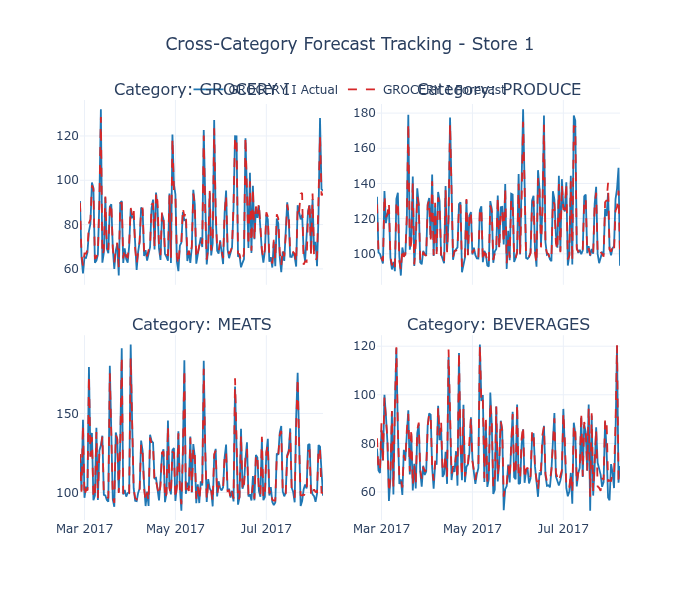

In [4]:
store_families = df_eval.filter(pl.col("store_nbr") == SELECTED_STORE)["family"].unique().to_list()

fig_multi = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=[f"Category: {fam}" for fam in store_families],
    shared_xaxes=True,
    vertical_spacing=0.12,
)

for idx, fam in enumerate(store_families):
    r = (idx // 2) + 1
    c = (idx % 2) + 1
    sub_df = (
        df_eval
        .filter((pl.col("store_nbr") == SELECTED_STORE) & (pl.col("family") == fam))
        .sort("date")
        .to_pandas()
    )
    
    fig_multi.add_trace(
        go.Scatter(
            x=sub_df["date"],
            y=sub_df["unit_sales"],
            name=f"{fam} Actual",
            line=dict(color="#1f77b4", width=1.8),
            showlegend=(idx == 0),
        ),
        row=r,
        col=c,
    )
    fig_multi.add_trace(
        go.Scatter(
            x=sub_df["date"],
            y=sub_df["prediction"],
            name=f"{fam} Forecast",
            line=dict(color="#d62728", width=1.8, dash="dash"),
            showlegend=(idx == 0),
        ),
        row=r,
        col=c,
    )

fig_multi.update_layout(
    title=dict(text=f"Cross-Category Forecast Tracking - Store {SELECTED_STORE}", x=0.5),
    template="plotly_white",
    height=600,
    legend=dict(orientation="h", y=1.06, x=0.5, xanchor="center"),
)

fig_multi.show()

## 4. Cumulative Demand Trajectory & Volume Tracking

Cumulative demand curves verify whether the model is systematically under-forecasting or over-forecasting over time. Diverging trajectories indicate bias; parallel curves demonstrate volume calibration.

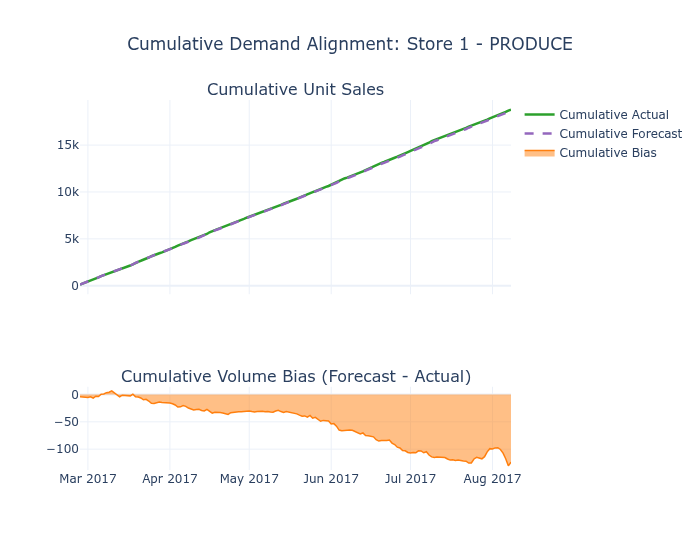

In [5]:
cum_df = ts_df.copy()
cum_df["cum_actual"] = cum_df["unit_sales"].cumsum()
cum_df["cum_predicted"] = cum_df["prediction"].cumsum()
cum_df["cum_bias"] = cum_df["cum_predicted"] - cum_df["cum_actual"]

fig_cum = make_subplots(
    rows=2,
    cols=1,
    row_heights=[0.7, 0.3],
    shared_xaxes=True,
    subplot_titles=("Cumulative Unit Sales", "Cumulative Volume Bias (Forecast - Actual)"),
)

fig_cum.add_trace(
    go.Scatter(x=cum_df["date"], y=cum_df["cum_actual"], name="Cumulative Actual", line=dict(color="#2ca02c", width=2.5)),
    row=1,
    col=1,
)
fig_cum.add_trace(
    go.Scatter(x=cum_df["date"], y=cum_df["cum_predicted"], name="Cumulative Forecast", line=dict(color="#9467bd", width=2.5, dash="dash")),
    row=1,
    col=1,
)
fig_cum.add_trace(
    go.Scatter(
        x=cum_df["date"],
        y=cum_df["cum_bias"],
        fill="tozeroy",
        name="Cumulative Bias",
        line=dict(color="#ff7f0e", width=1.5),
    ),
    row=2,
    col=1,
)

fig_cum.update_layout(
    title=dict(text=f"Cumulative Demand Alignment: Store {SELECTED_STORE} - {SELECTED_FAMILY}", x=0.5),
    template="plotly_white",
    height=550,
    hovermode="x unified",
)

fig_cum.show()

## 5. Promotional Lift Responsiveness

Validates how accurately the model captures promotional elasticity. We compute the average sales during promotional vs. non-promotional days for actuals and predictions across all categories.

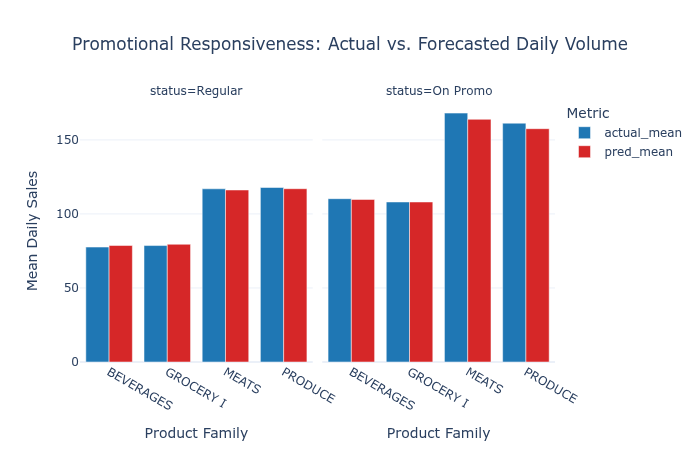

In [6]:
promo_summary = (
    df_eval
    .group_by(["family", "onpromotion"])
    .agg(
        actual_mean=pl.col("unit_sales").mean(),
        pred_mean=pl.col("prediction").mean(),
    )
    .with_columns(
        status=pl.when(pl.col("onpromotion") == 1).then(pl.lit("On Promo")).otherwise(pl.lit("Regular"))
    )
    .sort(["family", "onpromotion"])
    .to_pandas()
)

fig_promo = px.bar(
    promo_summary,
    x="family",
    y=["actual_mean", "pred_mean"],
    barmode="group",
    facet_col="status",
    title="Promotional Responsiveness: Actual vs. Forecasted Daily Volume",
    labels={"value": "Mean Daily Sales", "variable": "Metric", "family": "Product Family"},
    color_discrete_map={"actual_mean": "#1f77b4", "pred_mean": "#d62728"},
    template="plotly_white",
    height=450,
)

fig_promo.update_layout(title_x=0.5)
fig_promo.show()

## 6. Store x Product Family Error Matrix (NWRMSLE Heatmap)

The official competition metric is NWRMSLE. This heatmap provides an executive overview of performance across the store-family network, distinguishing high-performing segments from areas requiring model refinement.

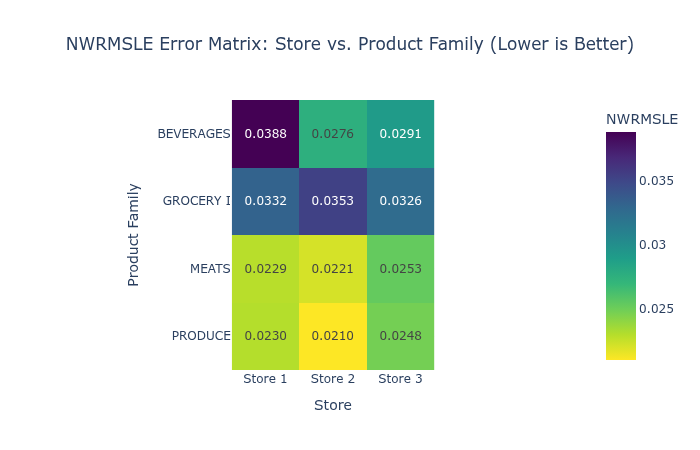

In [7]:
matrix_data = []
for (s, f), grp in df_eval.group_by(["store_nbr", "family"]):
    actuals = grp["unit_sales"].to_numpy()
    predictions = grp["prediction"].to_numpy()
    weights = grp["weight"].to_numpy() if "weight" in grp.columns else None
    score = nwrmsle_numpy(actuals, predictions, weights)
    matrix_data.append({"store_nbr": f"Store {s}", "family": f, "nwrmsle": round(score, 4)})

df_matrix = pl.DataFrame(matrix_data).to_pandas()
pivot_table = df_matrix.pivot(index="family", columns="store_nbr", values="nwrmsle")

fig_heat = px.imshow(
    pivot_table,
    text_auto=".4f",
    color_continuous_scale="Viridis_r",
    title="NWRMSLE Error Matrix: Store vs. Product Family (Lower is Better)",
    labels=dict(x="Store", y="Product Family", color="NWRMSLE"),
    template="plotly_white",
    height=450,
)

fig_heat.update_layout(title_x=0.5)
fig_heat.show()

## 7. Executive Summary Table

Summary of forecast quality across perishable status ($w=1.25$ for MEATS/PRODUCE vs. $w=1.00$ for BEVERAGES/GROCERY I).

In [8]:
summary_rows = []
for is_perish, label in [(True, "Perishable (w=1.25)"), (False, "Non-Perishable (w=1.00)")]:
    sub = df_eval.filter(pl.col("weight") > 1.1 if is_perish else pl.col("weight") <= 1.1)
    act = sub["unit_sales"].to_numpy()
    prd = sub["prediction"].to_numpy()
    w = sub["weight"].to_numpy()
    score = nwrmsle_numpy(act, prd, w)
    mae = float(np.mean(np.abs(act - prd)))
    wape = float(np.sum(np.abs(act - prd)) / np.sum(act)) * 100
    summary_rows.append({
        "Segment": label,
        "NWRMSLE": f"{score:.4f}",
        "MAE (units)": f"{mae:.2f}",
        "WAPE (%)": f"{wape:.2f}%",
        "Total Actual Units": f"{int(np.sum(act)):,}",
        "Total Predicted Units": f"{int(np.sum(prd)):,}",
    })

try:
    from IPython.display import display
    display(pl.DataFrame(summary_rows))
except ImportError:
    print(pl.DataFrame(summary_rows))


Segment,NWRMSLE,MAE (units),WAPE (%),Total Actual Units,Total Predicted Units
str,str,str,str,str,str
"""Perishable (w=1.25)""","""0.0232""","""2.38""","""1.91%""","""122,459""","""121,196"""
"""Non-Perishable (w=1.00)""","""0.0330""","""1.83""","""2.22%""","""81,284""","""82,050"""
